[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/option-pricing-python/blob/main/06_option_strategies.ipynb)

# 6. Option strategies

Classic strategies built from calls and puts, priced with Black-Scholes, with their profit at
expiry, maximum profit, maximum loss and break-even points.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def bs_price(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [3]:
S, T, r, sigma = 100, 0.25, 0.03, 0.20

# each leg: (type, strike, quantity)   quantity > 0 = buy, < 0 = sell
strategies = {
    "Bull call spread": [("call", 95, 1), ("call", 105, -1)],
    "Long straddle":    [("call", 100, 1), ("put", 100, 1)],
    "Long strangle":    [("call", 105, 1), ("put", 95, 1)],
    "Butterfly":        [("call", 90, 1), ("call", 100, -2), ("call", 110, 1)],
    "Iron condor":      [("put", 85, 1), ("put", 90, -1), ("call", 110, -1), ("call", 115, 1)],
}

def payoff(kind, K, ST):
    return np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)

ST = np.linspace(60, 140, 1601)
rows, profits = [], {}
for name, legs in strategies.items():
    cost = sum(q * bs_price(S, K, T, r, sigma, kind) for kind, K, q in legs)
    profit = sum(q * payoff(kind, K, ST) for kind, K, q in legs) - cost * np.exp(r * T)
    crossing = np.where(np.diff(np.sign(profit)) != 0)[0]
    unlimited = profit[-1] > profit[-2]                 # still rising when the stock goes up
    max_profit = "unlimited" if unlimited else f"{profit.max():.2f}"
    breakevens = ", ".join(f"{b:.1f}" for b in ST[crossing])
    rows.append((name, cost, max_profit, profit.min(), breakevens))
    profits[name] = profit

print("cost < 0 means a credit is received")
print(f"{'strategy':18s} {'cost':>7s} {'max profit':>11s} {'max loss':>9s}   break-even")
for name, cost, mx, mn, be in rows:
    print(f"{name:18s} {cost:7.2f} {mx:>11s} {mn:9.2f}   {be}")

cost < 0 means a credit is received
strategy              cost  max profit  max loss   break-even
Bull call spread      5.07        4.89     -5.11   100.1
Long straddle         7.97   unlimited     -8.03   92.0, 108.0
Long strangle         3.98   unlimited     -4.01   91.0, 109.0
Butterfly             3.66        6.31     -3.69   93.7, 106.3
Iron condor          -1.07        1.08     -3.92   88.9, 111.1


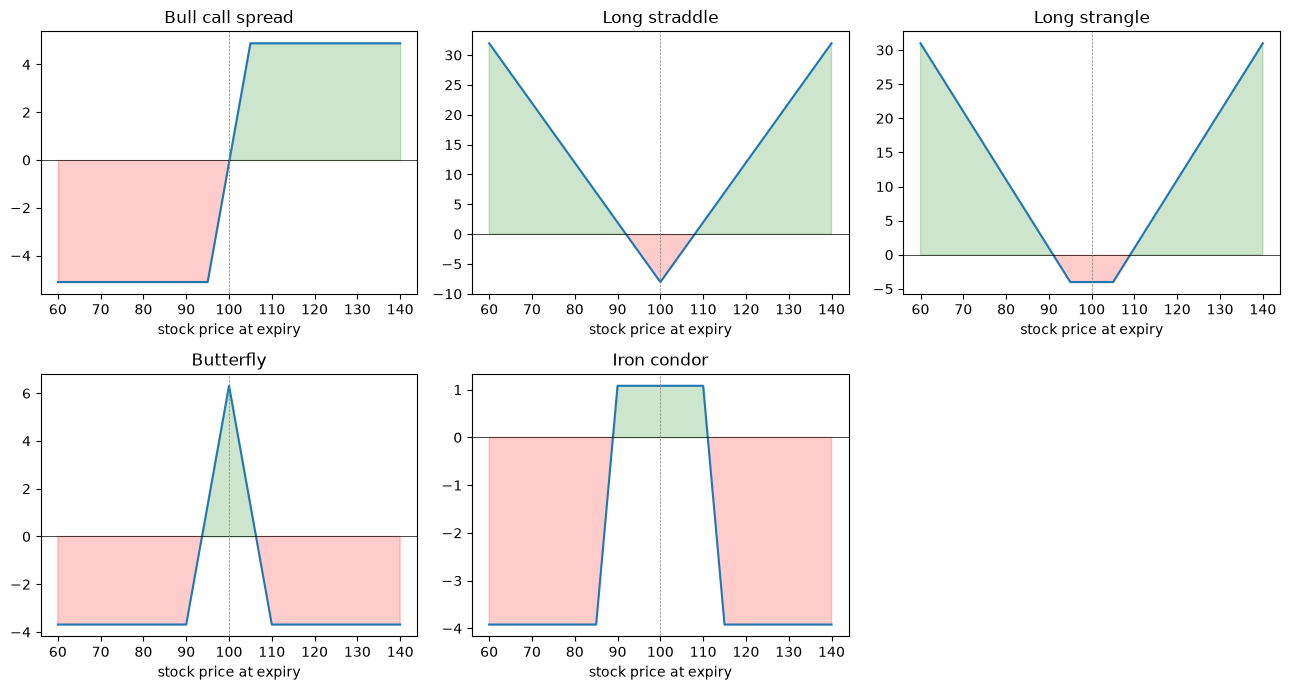

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (name, profit) in zip(axes.flat, profits.items()):
    ax.plot(ST, profit)
    ax.axhline(0, color="k", lw=0.5)
    ax.axvline(S, color="grey", ls="--", lw=0.5)
    ax.fill_between(ST, profit, 0, where=profit > 0, alpha=0.2, color="green")
    ax.fill_between(ST, profit, 0, where=profit < 0, alpha=0.2, color="red")
    ax.set_title(name); ax.set_xlabel("stock price at expiry")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

- **Bull call spread:** bet on a moderate rise, cheaper than a call but the gain is capped.
- **Straddle / strangle:** bet on a large move in either direction (long volatility).
- **Butterfly / iron condor:** bet that the stock stays in a range (short volatility), with a
  limited loss.